# 6 · Designing metrics for tasks

Everything so far works for *any* metric $G$.  Choosing $G$ is how a task is expressed:
whatever is expensive under $G$, geodesics avoid.  This notebook shows three designs:

1. **Pull-back metric** $J^\top J$ — short end-effector paths (and a lesson about the NES
   parameterisation for very anisotropic metrics);
2. **Stability-aware metric** — a cart-pole that keeps its pendulum low when it has far to go;
3. **Obstacles** — hard obstacles for the grid solver, a smooth speed field for NES, and a
   metric that keeps clearance.

Each problem is solved with the grid solver (notebook 2) and with NES (notebook 3) side by side.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, rfm, nes, obstacles as obs, plotting as P
from geodf.robots import PlanarArm, CartPole

torch.manual_seed(0)
pi = np.pi
arm = PlanarArm()
B = ((-pi, pi), (-pi, pi))
RETRAIN = False


def fit_nes(name, G, bounds, metric_factor=False):
    """NES for metric G on the box `bounds` (loads checkpoints/nes_<name>.pt if present)."""
    lo, hi = [b[0] for b in bounds], [b[1] for b in bounds]
    model = nes.NES(lo, hi, hidden=(128, 128, 128), metric=G if metric_factor else None)
    nes.train_or_load(model, f"checkpoints/nes_{name}.pt", lambda: nes.train(
        model, nes.uniform_pair_sampler(lo, hi, 1024), lambda q, w: torch.linalg.inv(G(q)),
        steps=15000, log_every=3000), retrain=RETRAIN)
    return model.eval()


def nes_field(model, G, grid, source):
    Q = torch.as_tensor(grid.points.reshape(-1, 2), dtype=torch.float32)
    U, V = nes.geodesic_flow(model, torch.as_tensor(source, dtype=torch.float32).expand_as(Q), Q, G, normalize=False)
    return U.numpy().reshape(grid.n), V.numpy().reshape(grid.n + (2,))


def nes_paths(model, G, source, starts, step=0.01):
    src = torch.as_tensor(source, dtype=torch.float32).repeat(len(starts), 1)
    return nes.backtrack(model, src, torch.as_tensor(np.asarray(starts), dtype=torch.float32), G,
                         step=step, tol=0.03, max_steps=4000)


colors = ["tab:blue", "tab:green", "tab:purple", "tab:orange"]

## 1. Pull-back metric: short end-effector paths

With the forward kinematics $x=f(q)$ and its Jacobian $J(q)$, the end-effector speed is
$\|\dot x\|=\|J\dot q\|=\sqrt{\dot q^\top J^\top J\,\dot q}$.  So under

$$G(q)=J(q)^\top J(q)+\lambda I$$

the length of a joint-space path is (up to the small $\lambda$ term) the length of the path drawn
by the end-effector, and geodesics move the end-effector along the shortest task-space path —
a straight line whenever it can be followed without passing a singular configuration.  The
small $\lambda=0.01$ keeps $G$ invertible at singular configurations ($q_2=0,\pm\pi$).

**A note on the NES parameterisation.**  NES writes $U=\|q_e-q_s\|\,\sigma(u_\theta)$: the
network learns the ratio between the geodesic and the Euclidean distance.  Close to the source
this ratio is $\sqrt{\hat\Delta^\top G(q_s)\hat\Delta}$ for the direction $\hat\Delta$ from $q_s$
— it depends on the direction, so it is discontinuous at $q_s=q_e$.  A continuous network can only
approximate it; for mildly anisotropic metrics (the kinetic-energy metric: ratio varies by ~6x)
the error is small, but for $J^\top J$ the eigenvalues of $G$ differ by up to ~1000x, the ratio
varies by ~30x with direction, and training converges to a wrong solution (a small eikonal loss,
but not the distance).  The fix is to put the metric into the factor:

$$U_\theta=d_G(q_s,q_e)\,\sigma(u_\theta),\qquad d_G=\sqrt{\Delta^\top G\big(\tfrac{q_s+q_e}2\big)\Delta},\ \Delta=q_e-q_s,$$

which is still symmetric and zero only at $q_s=q_e$, and exact to first order near the source; the
network then only learns a correction close to 1 (`NES(..., metric=G)`).

loaded checkpoints/nes_pullback.pt (trained in 122s)


         start  straight EE line  grid solver    NES  joint-space line
   [-0.8  0.4]              5.30         5.30   5.30              6.34
     [2.6 0.6]              5.01         5.01   5.01              5.84
     [2.8 2. ]              4.77         4.78   4.77              6.48
   [-2.   2.4]              3.64         3.64   3.64              4.51


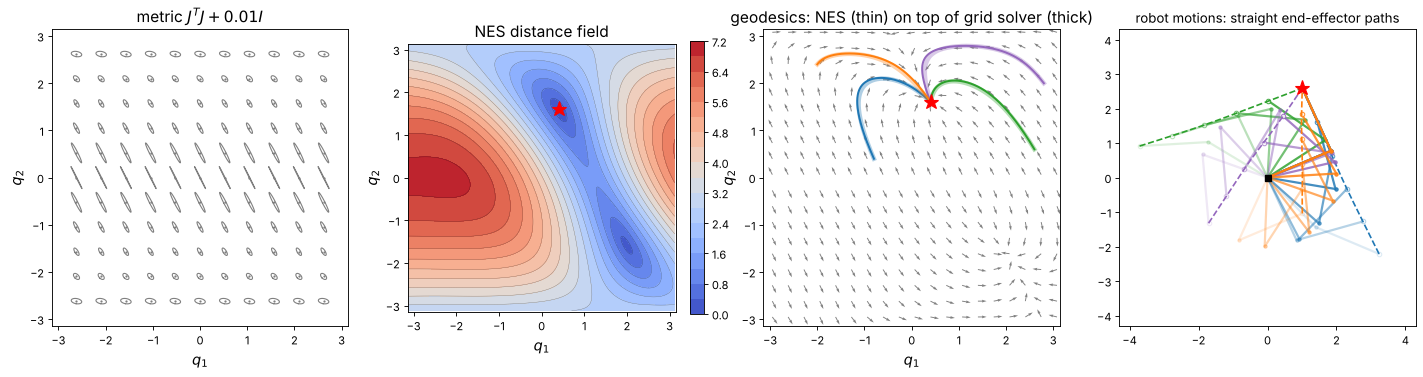

In [2]:
G_pb = metrics.pullback(arm, reg=0.01)
q_s = np.array([0.4, 1.6])
starts = np.array([[-0.8, 0.4], [2.6, 0.6], [2.8, 2.0], [-2.0, 2.4]])
sol = rfm.solve(G_pb, B, 150, q_s)
p_rfm = sol.backtrack(starts, step=0.005)
m_pb = fit_nes("pullback", G_pb, B, metric_factor=True)
U_nn, V_nn = nes_field(m_pb, G_pb, sol.grid, q_s)
p_nn = nes_paths(m_pb, G_pb, q_s, starts, step=0.005)

ee_len = lambda p: np.sum(np.linalg.norm(np.diff(arm.fk(torch.as_tensor(p, dtype=torch.float64)).numpy(), axis=0), axis=1))
x_s = arm.fk(torch.as_tensor(q_s[None]))[0].numpy()
print(f"{'start':>14s} {'straight EE line':>17s} {'grid solver':>12s} {'NES':>6s} {'joint-space line':>17s}")
for k, s in enumerate(starts):
    x0 = arm.fk(torch.as_tensor(s[None]))[0].numpy()
    print(f"{str(s):>14s} {np.linalg.norm(x_s - x0):17.2f} {ee_len(p_rfm[k]):12.2f} {ee_len(p_nn[k]):6.2f} "
          f"{ee_len(np.linspace(s, q_s, 300)):17.2f}")

fig, axs = plt.subplots(1, 4, figsize=(22, 5.2))
P.metric_ellipses(axs[0], G_pb, density=11)
P.setup_ax(axs[0], title="metric $J^TJ+0.01I$")
cf = P.field(axs[1], sol.grid.X, sol.grid.Y, U_nn)
fig.colorbar(cf, ax=axs[1], fraction=0.046)
axs[1].plot(*q_s, "r*", ms=14)
P.setup_ax(axs[1], title="NES distance field")
P.quiver(axs[2], sol.grid.X, sol.grid.Y, -V_nn, sub=8, color="gray")
for pr, pn, c in zip(p_rfm, p_nn, colors):
    axs[2].plot(*pr.T, color=c, lw=4, alpha=0.35)
    axs[2].plot(*pn.T, color=c, lw=1.8)
axs[2].plot(*q_s, "r*", ms=14)
P.setup_ax(axs[2], title="geodesics: NES (thin) on top of grid solver (thick)")
for p, c in zip(p_nn, colors):
    P.arm_motion(axs[3], arm, p, c, n=6)
axs[3].plot(*x_s, "r*", ms=14)
axs[3].set_title("robot motions: straight end-effector paths")
plt.show()

The end-effector travels exactly the straight-line distance, although the joint-space paths are
curved; the straight joint-space line would make it travel 15-35 % further.

Note the second valley of the distance field near $(2,-1.6)$: it is the *other* arm
configuration with the same end-effector position.  To switch between the two, the arm has to
pass through a singular configuration — here fully stretched, with the end-effector at the edge
of the workspace (radius 4) — so the end-effector travels out and back, about
$2(4-\|x_s\|)\approx2.4$.  That is small compared with most other configurations, hence the
valley, but it is not zero.

## 2. Stability-aware metric: a cart-pole that keeps the pole low

A cart (position $x$) carries a pendulum (angle $\theta$, $\theta=0$ = upright, high potential
energy).  Scaling the inertia metric by the normalised potential energy $\tilde P\in[0,1]$,

$$G(x,\theta)=M(\theta)\,\big(1+\epsilon\,\tilde P(\theta)\big),\qquad \epsilon=2,$$

makes the metric three times larger with the pole up than with the pole down (lengths
$\sqrt3\approx1.7$ times longer).  The
goal is the upright pole at $x=9$; the motions start with the pole horizontal at three
distances.

loaded checkpoints/nes_cartpole.pt (trained in 261s)


start x = 7: largest pole angle from upright  grid 1.58 rad, NES 1.57 rad   (pi = hanging down)
start x = 4: largest pole angle from upright  grid 2.97 rad, NES 2.95 rad   (pi = hanging down)
start x = 1: largest pole angle from upright  grid 3.13 rad, NES 3.20 rad   (pi = hanging down)


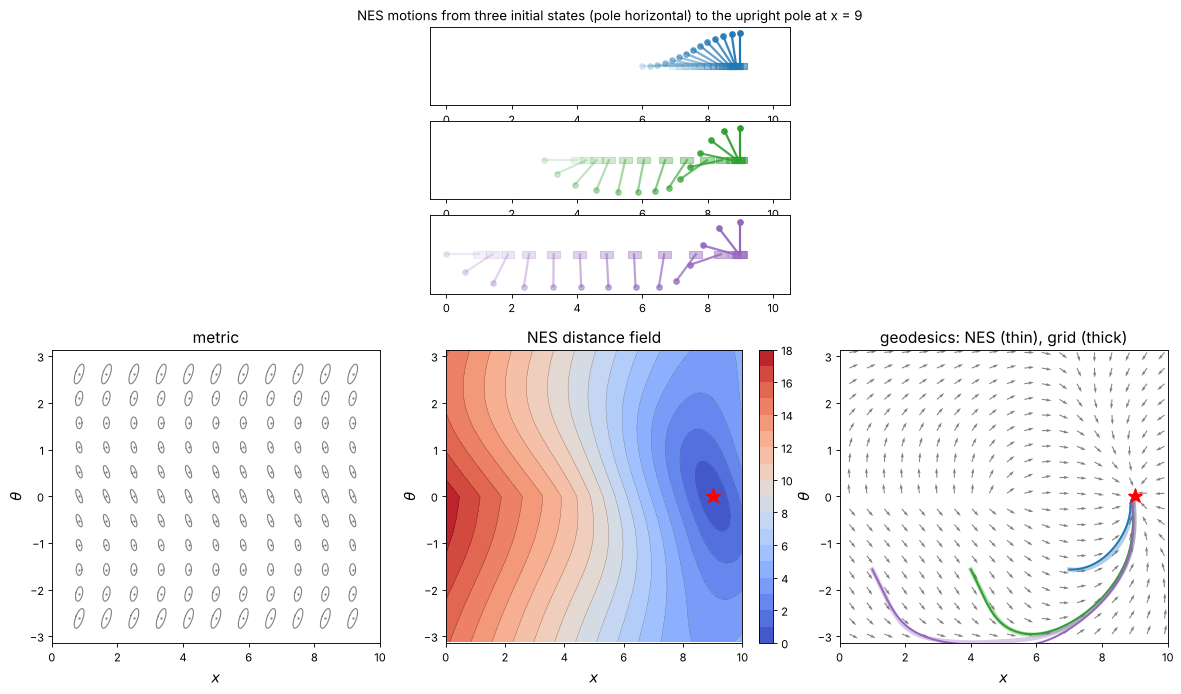

In [3]:
cp = CartPole()
G_sta = metrics.stability_aware(cp, eps=2.0)
Bc = ((0.0, 10.0), (-pi, pi))
goal = np.array([9.0, 0.0])
cstarts = np.array([[7.0, -pi / 2], [4.0, -pi / 2], [1.0, -pi / 2]])
solc = rfm.solve(G_sta, Bc, (150, 150), goal)
pc_rfm = solc.backtrack(cstarts, step=0.01)
m_cp = fit_nes("cartpole", G_sta, Bc)
Uc_nn, Vc_nn = nes_field(m_cp, G_sta, solc.grid, goal)
pc_nn = nes_paths(m_cp, G_sta, goal, cstarts)
for s, pr, pn in zip(cstarts, pc_rfm, pc_nn):
    print(f"start x = {s[0]:.0f}: largest pole angle from upright  grid {np.abs(pr[:, 1]).max():.2f} rad, "
          f"NES {np.abs(pn[:, 1]).max():.2f} rad   (pi = hanging down)")

fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.1])
top = gs[0].subgridspec(3, 1)
for k, (p, c) in enumerate(zip(pc_nn, colors)):
    ax = fig.add_subplot(top[k])
    for j, i in enumerate(np.linspace(0, len(p) - 1, 14).astype(int)):
        P.draw_cartpole(ax, p[i, 0], p[i, 1], color=c, alpha=0.15 + 0.85 * j / 13)
    ax.set_xlim(-0.5, 10.5); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal"); ax.set_yticks([])
    if k == 0:
        ax.set_title("NES motions from three initial states (pole horizontal) to the upright pole at x = 9")
bot = gs[1].subgridspec(1, 3)
ax = fig.add_subplot(bot[0])
P.metric_ellipses(ax, G_sta, bounds=Bc, density=11)
P.setup_ax(ax, bounds=Bc, labels=("$x$", r"$\theta$"), title="metric", equal=False)
ax = fig.add_subplot(bot[1])
cf = P.field(ax, solc.grid.X, solc.grid.Y, Uc_nn)
fig.colorbar(cf, ax=ax, fraction=0.046)
ax.plot(*goal, "r*", ms=14)
P.setup_ax(ax, bounds=Bc, labels=("$x$", r"$\theta$"), title="NES distance field", equal=False)
ax = fig.add_subplot(bot[2])
P.quiver(ax, solc.grid.X, solc.grid.Y, -Vc_nn, sub=8, color="gray")
for pr, pn, c in zip(pc_rfm, pc_nn, colors):
    ax.plot(*pr.T, color=c, lw=4, alpha=0.35)
    ax.plot(*pn.T, color=c, lw=1.8)
ax.plot(*goal, "r*", ms=14)
P.setup_ax(ax, bounds=Bc, labels=("$x$", r"$\theta$"), title="geodesics: NES (thin), grid (thick)", equal=False)
plt.show()

No mode switching is programmed: the short move keeps the pole near horizontal, while the
longer moves first let the pole swing down (cheap, stable configurations), travel, and lift it
only near the goal.  The geodesics simply dwell in the low-energy region as long as possible.

## 3. Obstacles

### 3a. Hard obstacles and why NES needs a smooth version

Two discs in the workspace define obstacles in configuration space: a configuration collides if
one of the links intersects a disc.  The grid solver handles them by giving colliding cells an
infinite cost — the front of fast marching can only propagate through free cells, so the
geodesics go around.

This does not transfer to a network:
* with hard obstacles $U=+\infty$ inside them and $U$ is not smooth at their boundary, which a
  smooth, finite MLP cannot represent;
* if we simply do not sample inside the obstacles, nothing in the loss constrains the field
  there, and a field that "passes through" an obstacle satisfies the eikonal loss on the
  free-space samples just as well.

The standard remedy (as in NTFields) is a **speed field** $s(q)\in[s_{min},1]$ computed from
the clearance $d(q)$ (distance between links and obstacles): $G_s(q)=G(q)/s(q)^2$, with
$s=1$ for $d\ge0.5$ and $s=0.2$ in contact.  The problem is now smooth and finite everywhere;
crossing an obstacle costs $1/s_{min}=5$ times more per unit length, so for obstacles like these
going around is cheaper than going through.

loaded checkpoints/nes_obstacles_cspace.pt (trained in 96s)


start [-2.6 -2.6]: smallest clearance along the path  grid/hard 0.086   NES/speed field 0.086
start [ 2.5 -1. ]: smallest clearance along the path  grid/hard 0.063   NES/speed field 0.393
start [1.5 2.5]: smallest clearance along the path  grid/hard 0.133   NES/speed field 0.453
start [ 0.5 -2.8]: smallest clearance along the path  grid/hard 0.458   NES/speed field 0.461
start [2.9 2.8]: smallest clearance along the path  grid/hard 0.208   NES/speed field 0.453


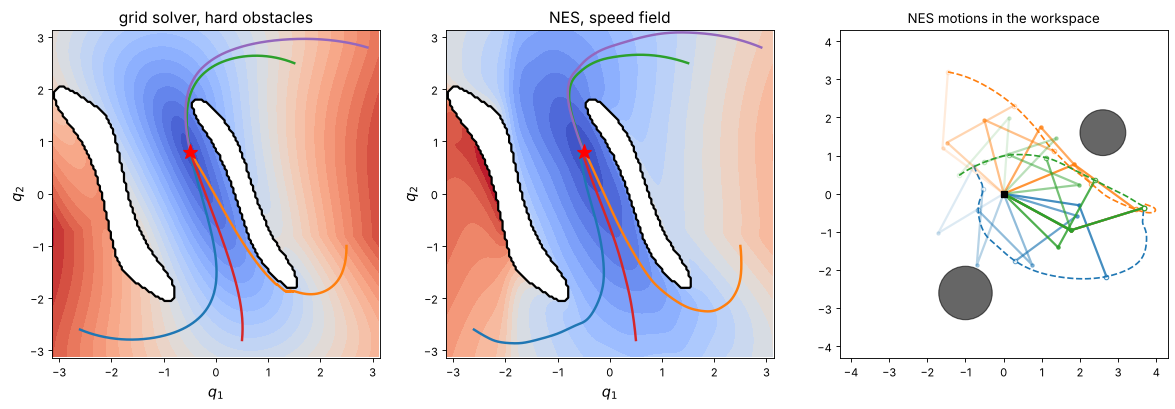

In [4]:
discs_c, discs_r = [(2.6, 1.6), (-1.0, -2.6)], [0.6, 0.7]
clear = obs.arm_clearance(arm, discs_c, discs_r)
G_ke = metrics.kinetic_energy(arm)
G_soft = obs.speed_scaled(G_ke, clear)               # G / s(q)^2
q_s = np.array([-0.5, 0.8])
grid = rfm.Grid2D(B, 150)
mask = clear(torch.as_tensor(grid.points)).numpy() < 0
ostarts = np.array([[-2.6, -2.6], [2.5, -1.0], [1.5, 2.5], [-2.8, 1.5], [0.5, -2.8], [2.9, 2.8]])
ostarts = ostarts[clear(torch.as_tensor(ostarts)).numpy() > 0.05]     # keep collision-free starts

sol_hard = rfm.solve(G_ke, B, 150, q_s, mask=mask)  # grid solver, hard obstacles
p_hard = sol_hard.backtrack(ostarts, step=0.01)
m_ob = fit_nes("obstacles_cspace", G_soft, B)       # NES, speed field
Uo, Vo = nes_field(m_ob, G_soft, grid, q_s)
po = nes_paths(m_ob, G_soft, q_s, ostarts)
for k, s in enumerate(ostarts):
    print(f"start {s}: smallest clearance along the path  grid/hard {clear(torch.as_tensor(p_hard[k])).min():.3f}"
          f"   NES/speed field {clear(torch.as_tensor(po[k]).double()).min():.3f}")

fig, axs = plt.subplots(1, 3, figsize=(18, 5.6))
for ax, U, V, paths, title in [(axs[0], sol_hard.U, sol_hard.flow, p_hard, "grid solver, hard obstacles"),
                               (axs[1], Uo, Vo, po, "NES, speed field")]:
    ax.contourf(grid.X, grid.Y, np.where(mask, np.nan, U), 25, cmap="coolwarm")
    ax.contour(grid.X, grid.Y, mask.astype(float), [0.5], colors="k", linewidths=2)
    for k, p in enumerate(paths):
        ax.plot(*p.T, color=plt.get_cmap("tab10")(k), lw=2.2)
    ax.plot(*q_s, "r*", ms=14)
    P.setup_ax(ax, title=title)
for c, r in zip(discs_c, discs_r):
    axs[2].add_patch(plt.Circle(c, r, color="k", alpha=0.6))
for k, p in enumerate(po[:3]):
    P.arm_motion(axs[2], arm, p, plt.get_cmap("tab10")(k), n=6)
axs[2].set_title("NES motions in the workspace")
plt.show()

With hard obstacles the paths that go around an obstacle pass close to it (clearance 0.06-0.2,
limited by the grid resolution).  The speed field, besides making the problem learnable, keeps
more clearance because motion close to obstacles is more expensive.

### 3b. A metric that keeps clearance: penalise motion towards obstacles

A speed field slows down motion in *all* directions near obstacles.  A Riemannian metric can be
more selective: penalise only motion **along the obstacle normal** $r_1=\nabla d/\|\nabla d\|$,
and leave tangential motion ($r_2\perp r_1$) cheap:

$$G(x)=w(x)\,r_1r_1^\top+r_2r_2^\top,\qquad w=\phi/\phi_{min},\quad
  \phi=\mathrm{sigmoid}\big(\alpha(\tau-d)\big)(1-\phi_{min})+\phi_{min},$$

so $G\approx I$ far from obstacles, while within a distance $\sim\tau$ the metric along the normal is
up to $1/\phi_{min}=10$ times larger (moving straight towards an obstacle is ~3 times longer).  Below, a point robot in the plane: (a) plain Euclidean
metric, (b) this obstacle metric (both with the same speed field for NES).

loaded checkpoints/nes_plane_iso.pt (trained in 94s)


(a) Euclidean metric: smallest clearance per path [0.4  0.45 0.32 0.32]
loaded checkpoints/nes_plane_riem.pt (trained in 108s)


(b) obstacle metric: smallest clearance per path [0.48 0.65 0.33 0.63]


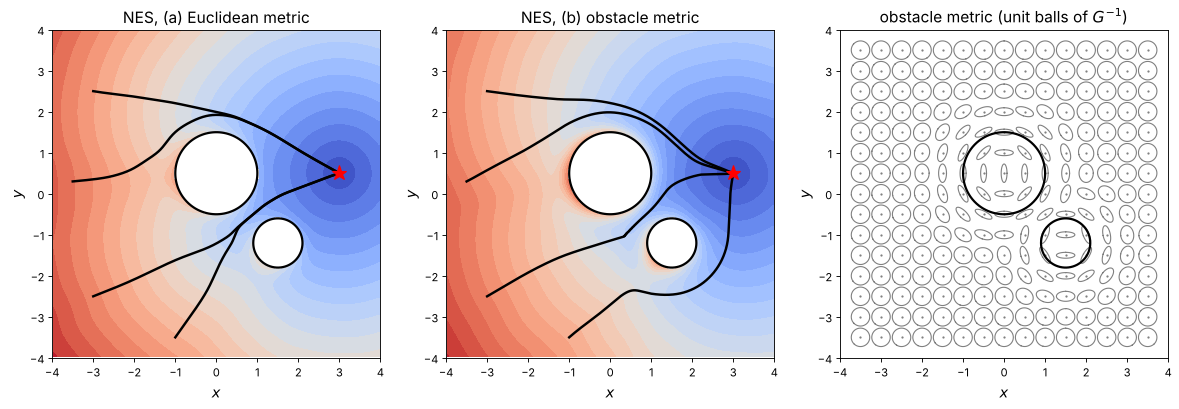

In [5]:
sdf = obs.disc_sdf([[0.0, 0.5], [1.5, -1.2]], [1.0, 0.6])
Bx = ((-4.0, 4.0), (-4.0, 4.0))
gx = rfm.Grid2D(Bx, 150)
in_obs = sdf(torch.as_tensor(gx.points)).numpy() < 0
goal_x = np.array([3.0, 0.5])
xstarts = np.array([(-3.5, 0.3), (-3.0, 2.5), (-3.0, -2.5), (-1.0, -3.5)])
G_obs = metrics.obstacle_metric(sdf, alpha=5.0, tau=0.5, phi_min=0.1)

fig, axs = plt.subplots(1, 3, figsize=(18, 5.8))
for ax, key, G, title in [(axs[0], "plane_iso", metrics.euclidean(), "(a) Euclidean metric"),
                          (axs[1], "plane_riem", G_obs, "(b) obstacle metric")]:
    G_s = obs.speed_scaled(G, sdf)
    m = fit_nes(key, G_s, Bx)
    U, _ = nes_field(m, G_s, gx, goal_x)
    paths = nes_paths(m, G_s, goal_x, xstarts)
    ax.contourf(gx.X, gx.Y, np.where(in_obs, np.nan, U), 25, cmap="coolwarm")
    ax.contour(gx.X, gx.Y, sdf(torch.as_tensor(gx.points)).numpy(), [0], colors="k", linewidths=2)
    for p in paths:
        ax.plot(*p.T, "k-", lw=2.2)
    ax.plot(*goal_x, "r*", ms=14)
    P.setup_ax(ax, bounds=Bx, labels=("$x$", "$y$"), title=f"NES, {title}")
    print(f"{title}: smallest clearance per path "
          f"{np.round([sdf(torch.as_tensor(p).double()).min().item() for p in paths], 2)}")
P.metric_ellipses(axs[2], G_obs, bounds=Bx, density=15)
axs[2].contour(gx.X, gx.Y, sdf(torch.as_tensor(gx.points)).numpy(), [0], colors="k", linewidths=2)
P.setup_ax(axs[2], bounds=Bx, labels=("$x$", "$y$"), title="obstacle metric (unit balls of $G^{-1}$)")
plt.show()

The ellipses (right) are flattened along the obstacle normals near the obstacles: moving
*towards* an obstacle is expensive, moving *around* it is not.  The geodesics therefore bend
around the obstacles earlier and with more clearance, while keeping smooth shapes.

**Summary.**  The method itself never changes — eikonal equation, distance field, geodesic
flow.  The task lives entirely in the metric: kinetic energy, energy conservation, task-space
distance, stability, obstacles, or combinations of them.